# 14 — Static Graph Baseline & GAT

**Goal:** test whether a static graph representation can exploit inter-cell relationships better than non-graph baselines on the **corrected 90-node Indonesian Kalimantan domain**.

This notebook is intentionally placed **after** Notebook 13 and **before** temporal GAT/GRU modeling.

---

## Main research question

> If every day is represented as a graph of Kalimantan grid cells, can graph message passing improve next-day hotspot prediction beyond models that treat each cell independently?

---

## Models compared

All neural models use the **same 20 benchmark node features** as the corrected LR baseline.

1. **LR20** — linear tabular baseline, no graph.
2. **MLP20** — nonlinear node-wise neural baseline, no graph.
3. **GCN20** — static graph convolution using the 150 km graph.
4. **GAT20** — static graph attention using the same 150 km graph.

The MLP control is important: if GAT beats LR but not MLP, the gain may come from nonlinear capacity rather than the graph itself.

Notebook 13's handcrafted `LR20 + Neighbor` result is loaded only as a **reference**, because it uses explicitly engineered spatial activity features and is not exactly the same input representation as the strict 20-feature models here.

---

## Graph

- Nodes: corrected Kalimantan cells from Notebook 12B.
- Working radius: **150 km**, carried forward from Notebook 13.
- Edges: static geographic neighbor relation.
- Self-loops: added inside GCN/GAT.
- Wind: **not used yet** in the main GAT.

Notebook 13 found wind to be exploratory rather than fully robust across radii, so wind is postponed to a later ablation.

---

## Time handling

This is a **static-per-day graph model**:

```text
Day t graph + day t node features
            ↓
       GCN / GAT
            ↓
Next-day hotspot label for every node
```

There is **no multi-day sequence encoder yet**. Temporal GAT/GRU comes next.

---

## Validation protocol

To avoid choosing neural-network training duration directly on August validation:

1. original training window: May 8–Jul 31;
2. last 14 training days are used as an **internal early-stopping tail**;
3. best epoch is selected using only that internal tail;
4. model is reinitialized and retrained on the **full May–Jul training window** for that many epochs;
5. August is evaluated once for model comparison;
6. September test remains unopened.

Neural models run with **3 random seeds** by default so results are not based on a single initialization.

## Environment note

This notebook uses **PyTorch only**; it does not require PyTorch Geometric.

The graph has only 90 nodes, so the GCN/GAT layers are implemented with dense 90×90 adjacency/attention matrices. This keeps the setup simple and makes CPU training practical.

If PyTorch is not installed in the active environment, install it first, for example in the project virtual environment:

```bash
pip install torch
```

Google Colab normally already includes PyTorch.

In [3]:
# 1. Imports and reproducibility

from pathlib import Path
import copy
import json
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

try:
    import joblib
except ImportError:
    joblib = None

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError as exc:
    raise ImportError(
        "PyTorch is required for Notebook 14. Install it in the active environment, "
        "for example with: pip install torch"
    ) from exc

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
SEEDS = [42, 123, 2026]

pd.set_option("display.max_columns", 150)
pd.set_option("display.width", 200)


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_all_seeds(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Device         :", DEVICE)
print("Seeds          :", SEEDS)

PyTorch version: 2.14.0+cpu
Device         : cpu
Seeds          : [42, 123, 2026]


## 2. Resolve project paths

In [4]:
# 2. Project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    ml_candidate = (
        candidate
        / "data"
        / "processed"
        / "spatial_corrected"
        / "karhut_ml_dataset_kalimantan_corrected.csv"
    )
    nodes_candidate = (
        candidate
        / "data"
        / "intermediate"
        / "spatial_corrected"
        / "kalimantan_graph_nodes_corrected.csv"
    )
    if ml_candidate.exists() and nodes_candidate.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not detect the project root. Run Notebook 12B and 12C first."
    )

ML_INPUT = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spatial_corrected"
    / "karhut_ml_dataset_kalimantan_corrected.csv"
)

NODES_INPUT = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "spatial_corrected"
    / "kalimantan_graph_nodes_corrected.csv"
)

EDGE_INPUT = (
    PROJECT_ROOT
    / "model_results"
    / "wind_neighbor_analysis"
    / "graph_edges"
    / "kalimantan_directed_edges_r150km.csv"
)

N13_OVERALL_INPUT = (
    PROJECT_ROOT
    / "model_results"
    / "wind_neighbor_analysis"
    / "overall_ablation_r150km.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "static_graph_baseline"
)

FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = RESULTS_DIR / "models"
ARTIFACTS_DIR = RESULTS_DIR / "artifacts"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT       :", PROJECT_ROOT)
print("Corrected ML       :", ML_INPUT)
print("Corrected nodes    :", NODES_INPUT)
print("150-km edges       :", EDGE_INPUT)
print("Notebook 13 ref    :", N13_OVERALL_INPUT)
print("Results            :", RESULTS_DIR)

PROJECT_ROOT       : c:\Users\Asus\Documents\skripsi-karhut
Corrected ML       : c:\Users\Asus\Documents\skripsi-karhut\data\processed\spatial_corrected\karhut_ml_dataset_kalimantan_corrected.csv
Corrected nodes    : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\kalimantan_graph_nodes_corrected.csv
150-km edges       : c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\graph_edges\kalimantan_directed_edges_r150km.csv
Notebook 13 ref    : c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\overall_ablation_r150km.csv
Results            : c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline


## 3. Load corrected node-day data and graph nodes

In [5]:
# 3. Load corrected tables

ml = pd.read_csv(
    ML_INPUT,
    parse_dates=["date"],
)

nodes = pd.read_csv(
    NODES_INPUT,
)

ml = (
    ml
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

nodes = (
    nodes
    .sort_values("node_index")
    .reset_index(drop=True)
)

print("ML shape         :", ml.shape)
print("Nodes            :", nodes.shape)
print("Unique ML cells  :", ml["cell_id"].nunique())
print("Date range       :", ml["date"].min().date(), "→", ml["date"].max().date())

ML shape         : (11340, 37)
Nodes            : (90, 9)
Unique ML cells  : 90
Date range       : 2026-05-08 → 2026-09-10


## 4. Define the strict 20-feature input

GCN and GAT intentionally use the same 20 features as LR20 so the primary comparison has **feature parity**.

In [6]:
# 4. Feature definitions and integrity audit

fire_history_features = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

weather_features = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

features_20 = fire_history_features + weather_features
target_col = "target_fire_active_t1"

required_cols = {
    "cell_id",
    "grid_lat",
    "grid_lon",
    "date",
    target_col,
    "active_days_prev3_incl_t",
    "event_type_3d",
    *features_20,
}

missing = sorted(required_cols - set(ml.columns))
if missing:
    raise ValueError(f"Corrected ML file is missing columns: {missing}")

assert len(features_20) == 20
assert ml.duplicated(["cell_id", "date"]).sum() == 0
assert nodes["cell_id"].duplicated().sum() == 0
assert set(ml["cell_id"].unique()) == set(nodes["cell_id"].unique())
assert ml[features_20].isna().sum().sum() == 0

print("20-feature parity audit: PASSED")
print("Corrected nodes        :", len(nodes))

20-feature parity audit: PASSED
Corrected nodes        : 90


# PART A — Build the 150-km graph

## 5. Load Notebook 13 edges, with a geographic fallback

If the Notebook 13 edge CSV is missing, the notebook rebuilds the same 150-km geographic graph from node coordinates.

In [7]:
# 5. Load or rebuild 150-km directed edges

WORKING_RADIUS_KM = 150
EARTH_RADIUS_KM = 6371.0088


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    )

    return EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(a))


if EDGE_INPUT.exists():
    edges = pd.read_csv(EDGE_INPUT)
    print("Loaded Notebook 13 edges.")
else:
    print("Notebook 13 edge file not found; rebuilding 150-km graph.")

    rows = []
    node_records = list(
        nodes[["node_index", "cell_id", "grid_lat", "grid_lon"]].itertuples(index=False)
    )

    for source in node_records:
        for target in node_records:
            if source.cell_id == target.cell_id:
                continue

            distance = haversine_km(
                source.grid_lat,
                source.grid_lon,
                target.grid_lat,
                target.grid_lon,
            )

            if distance <= WORKING_RADIUS_KM:
                rows.append({
                    "source_node_index": source.node_index,
                    "source_cell_id": source.cell_id,
                    "source_lat": source.grid_lat,
                    "source_lon": source.grid_lon,
                    "target_node_index": target.node_index,
                    "target_cell_id": target.cell_id,
                    "target_lat": target.grid_lat,
                    "target_lon": target.grid_lon,
                    "distance_km": distance,
                })

    edges = pd.DataFrame(rows)

print("Directed edges:", len(edges))
print("Source cells  :", edges["source_cell_id"].nunique())
print("Target cells  :", edges["target_cell_id"].nunique())

Loaded Notebook 13 edges.
Directed edges: 590
Source cells  : 90
Target cells  : 90


## 6. Convert graph to matrix form

For message passing, matrix orientation is:

```text
A[target, source] = 1
```

so each target row aggregates messages from source-neighbor columns.

The 150-km graph is geographically symmetric in practice because each radius edge exists in both directions, but the implementation still keeps explicit source→target orientation.

In [8]:
# 6. Adjacency matrices

node_order = nodes[["node_index", "cell_id", "grid_lat", "grid_lon"]].copy()
node_order["node_pos"] = np.arange(len(node_order))

cell_to_pos = dict(zip(node_order["cell_id"], node_order["node_pos"]))

N_NODES = len(node_order)
A = np.zeros((N_NODES, N_NODES), dtype=np.float32)

for row in edges.itertuples(index=False):
    source_pos = cell_to_pos[row.source_cell_id]
    target_pos = cell_to_pos[row.target_cell_id]
    A[target_pos, source_pos] = 1.0

A_no_self = A.copy()
A_self = A + np.eye(N_NODES, dtype=np.float32)
A_self = np.clip(A_self, 0.0, 1.0)

degree = A_self.sum(axis=1)
d_inv_sqrt = np.power(degree, -0.5)
A_norm = (
    d_inv_sqrt[:, None]
    * A_self
    * d_inv_sqrt[None, :]
).astype(np.float32)

adj_mask = A_self.astype(bool)

symmetry_error = np.abs(A_no_self - A_no_self.T).sum()

print("Nodes                     :", N_NODES)
print("Directed non-self edges   :", int(A_no_self.sum()))
print("Mean non-self neighbors   :", A_no_self.sum(axis=1).mean())
print("Min / max neighbors       :", int(A_no_self.sum(axis=1).min()), "/", int(A_no_self.sum(axis=1).max()))
print("Adjacency symmetry error  :", float(symmetry_error))
print("Self loops after addition :", int(np.trace(A_self)))

Nodes                     : 90
Directed non-self edges   : 590
Mean non-self neighbors   : 6.5555553
Min / max neighbors       : 3 / 8
Adjacency symmetry error  : 0.0
Self loops after addition : 90


## 7. Graph geometry plot

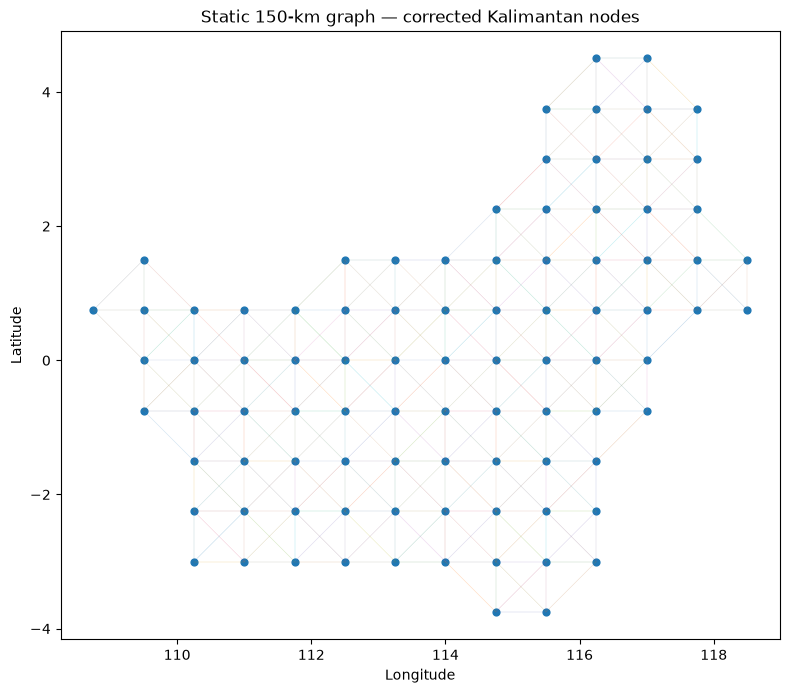

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\figures\01_static_graph_r150km.png


In [9]:
# 7. Graph geometry

fig, ax = plt.subplots(figsize=(8, 8))

for row in edges.itertuples(index=False):
    ax.plot(
        [row.source_lon, row.target_lon],
        [row.source_lat, row.target_lat],
        linewidth=0.35,
        alpha=0.16,
    )

ax.scatter(
    nodes["grid_lon"],
    nodes["grid_lat"],
    s=24,
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Static 150-km graph — corrected Kalimantan nodes")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()

path = FIGURES_DIR / "01_static_graph_r150km.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART B — Build daily graph tensors

## 8. Convert each date into a 90-node snapshot

For every date:

- `X[date, node, feature]` → 20 benchmark features;
- `y[date, node]` → next-day hotspot target;
- `eligible3[date, node]` → no local target-cell detection during `t-2 ... t`.

In [10]:
# 8. Daily tensors in fixed node order

all_dates = pd.DatetimeIndex(sorted(ml["date"].unique()))

X_list = []
y_list = []
eligible3_list = []
event3_list = []

for date in all_dates:
    day = ml[ml["date"].eq(date)][
        ["cell_id", *features_20, target_col, "active_days_prev3_incl_t", "event_type_3d"]
    ].copy()

    day = node_order[["cell_id", "node_pos"]].merge(
        day,
        on="cell_id",
        how="left",
        validate="one_to_one",
    ).sort_values("node_pos")

    if len(day) != N_NODES:
        raise AssertionError(f"Incomplete node snapshot on {date.date()}: {len(day)} rows")

    if day[features_20 + [target_col]].isna().any().any():
        raise AssertionError(f"Missing model values on {date.date()}")

    X_list.append(day[features_20].to_numpy(dtype=np.float32))
    y_list.append(day[target_col].to_numpy(dtype=np.float32))
    eligible3_list.append(day["active_days_prev3_incl_t"].eq(0).to_numpy())
    event3_list.append(day["event_type_3d"].astype(str).to_numpy())

X_raw = np.stack(X_list)
y_np = np.stack(y_list)
eligible3_np = np.stack(eligible3_list)
event3_np = np.stack(event3_list)

print("X raw shape     :", X_raw.shape)
print("y shape         :", y_np.shape)
print("Eligible3 shape :", eligible3_np.shape)
print("Dates           :", len(all_dates))

X raw shape     : (126, 90, 20)
y shape         : (126, 90)
Eligible3 shape : (126, 90)
Dates           : 126


## 9. Temporal masks and internal early-stopping tail

The **August validation set is not used to decide training epoch count**.

In [11]:
# 9. Temporal split masks

train_date_mask = all_dates < pd.Timestamp("2026-08-01")
val_date_mask = (
    (all_dates >= pd.Timestamp("2026-08-01"))
    & (all_dates < pd.Timestamp("2026-09-01"))
)
test_date_mask = all_dates >= pd.Timestamp("2026-09-01")

train_dates = all_dates[train_date_mask]
val_dates = all_dates[val_date_mask]
test_dates = all_dates[test_date_mask]

INTERNAL_VAL_DAYS = 14

if len(train_dates) <= INTERNAL_VAL_DAYS:
    raise ValueError("Training window is too short for the internal validation tail.")

internal_val_dates = train_dates[-INTERNAL_VAL_DAYS:]
fit_dates = train_dates[:-INTERNAL_VAL_DAYS]

fit_date_mask = all_dates.isin(fit_dates)
internal_val_mask = all_dates.isin(internal_val_dates)

summary = pd.DataFrame({
    "Block": ["Fit", "Internal early-stop", "Full train", "August validation", "September test"],
    "Start": [
        fit_dates.min(),
        internal_val_dates.min(),
        train_dates.min(),
        val_dates.min(),
        test_dates.min(),
    ],
    "End": [
        fit_dates.max(),
        internal_val_dates.max(),
        train_dates.max(),
        val_dates.max(),
        test_dates.max(),
    ],
    "Days": [
        len(fit_dates),
        len(internal_val_dates),
        len(train_dates),
        len(val_dates),
        len(test_dates),
    ],
})

display(summary)

,Block,Start,End,Days
0,Fit,2026-05-08,2026-07-17,71
1,Internal early-stop,2026-07-18,2026-07-31,14
2,Full train,2026-05-08,2026-07-31,85
3,August validation,2026-08-01,2026-08-31,31
4,September test,2026-09-01,2026-09-10,10


## 10. Standardize node features using May–July training data only

A single scaler is fit over all node rows from the full original training window. August and September statistics are not used.

In [12]:
# 10. Train-only feature scaling

scaler = StandardScaler()

train_rows_for_scaler = X_raw[train_date_mask].reshape(-1, len(features_20))
scaler.fit(train_rows_for_scaler)

X_scaled = scaler.transform(
    X_raw.reshape(-1, len(features_20))
).reshape(X_raw.shape).astype(np.float32)

print("Scaled feature mean on train rows (approx):", float(X_scaled[train_date_mask].mean()))
print("Scaled feature std on train rows  (approx):", float(X_scaled[train_date_mask].std()))

Scaled feature mean on train rows (approx): -6.382761430501205e-09
Scaled feature std on train rows  (approx): 1.0


## 11. Move tensors to selected device

In [13]:
# 11. Torch tensors

X_tensor = torch.tensor(X_scaled, dtype=torch.float32, device=DEVICE)
y_tensor = torch.tensor(y_np, dtype=torch.float32, device=DEVICE)

A_norm_tensor = torch.tensor(A_norm, dtype=torch.float32, device=DEVICE)
adj_mask_tensor = torch.tensor(adj_mask, dtype=torch.bool, device=DEVICE)

fit_idx = torch.tensor(np.where(fit_date_mask)[0], dtype=torch.long, device=DEVICE)
internal_val_idx = torch.tensor(np.where(internal_val_mask)[0], dtype=torch.long, device=DEVICE)
train_idx = torch.tensor(np.where(train_date_mask)[0], dtype=torch.long, device=DEVICE)
val_idx = torch.tensor(np.where(val_date_mask)[0], dtype=torch.long, device=DEVICE)
test_idx = torch.tensor(np.where(test_date_mask)[0], dtype=torch.long, device=DEVICE)

print("X tensor:", tuple(X_tensor.shape), X_tensor.device)
print("y tensor:", tuple(y_tensor.shape), y_tensor.device)

X tensor: (126, 90, 20) cpu
y tensor: (126, 90) cpu


# PART C — Strict non-graph LR20 benchmark

## 12. Reproduce LR20 on the corrected domain

In [14]:
# 12. LR20 benchmark

train_df = ml[ml["date"] < "2026-08-01"].copy()
val_df = ml[
    (ml["date"] >= "2026-08-01")
    & (ml["date"] < "2026-09-01")
].copy()

lr20 = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE,
        ),
    ),
])

lr_start = time.perf_counter()
lr20.fit(train_df[features_20], train_df[target_col].astype(int))
lr_training_seconds = time.perf_counter() - lr_start

lr_val_prob = lr20.predict_proba(val_df[features_20])[:, 1]
lr_val_y = val_df[target_col].astype(int).to_numpy()


def metric_dict(y_true, probability, threshold=0.50):
    y_true = np.asarray(y_true).astype(int)
    probability = np.asarray(probability)
    prediction = (probability >= threshold).astype(int)

    return {
        "PR-AUC": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "Accuracy": accuracy_score(y_true, prediction),
        "Threshold": threshold,
    }


lr_metrics = metric_dict(lr_val_y, lr_val_prob)

display(pd.DataFrame([{"Model": "LR20", **lr_metrics, "Training Seconds": lr_training_seconds}]))

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold,Training Seconds
0,LR20,0.955283,0.884426,0.86602,0.939742,0.901376,0.845878,0.5,0.133202


## 13. Notebook 13 handcrafted spatial reference

This is shown separately because it is not strict feature parity with GCN/GAT.

In [15]:
# 13. Optional Notebook 13 reference

n13_reference = None

if N13_OVERALL_INPUT.exists():
    n13_reference = pd.read_csv(N13_OVERALL_INPUT)
    display(n13_reference)
else:
    print("Notebook 13 overall-ablation CSV not found; skipping reference table.")

,Model,N Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold,Training Seconds
0,LR20,20,0.955283,0.884426,0.866020,0.939742,0.901376,0.845878,0.5,0.134799
1,LR20 + Neighbor,24,0.956645,0.884517,0.806297,0.967480,0.879565,0.801434,0.5,0.074905
2,LR20 + Neighbor + Wind,29,0.956863,0.885130,0.806387,0.966045,0.879025,0.800717,0.5,0.080909


# PART D — Neural baselines and graph layers

## 14. MLP20: nonlinear node-wise control

The MLP sees every node independently. It has **no adjacency matrix**.

In [16]:
# 14. Node-wise MLP

class NodeMLP(nn.Module):
    def __init__(self, in_dim, hidden1=32, hidden2=16, dropout=0.20):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.out = nn.Linear(hidden2, 1)
        self.dropout = dropout

    def forward(self, x, a_norm=None, adj_mask=None, return_attention=False):
        h = F.relu(self.fc1(x))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = F.relu(self.fc2(h))
        h = F.dropout(h, p=self.dropout, training=self.training)
        logits = self.out(h).squeeze(-1)
        if return_attention:
            return logits, None
        return logits

## 15. Dense GCN20

GCN aggregates standardized neighbor features through symmetrically normalized adjacency.

In [17]:
# 15. Dense GCN

class DenseGCNLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim)

    def forward(self, x, a_norm):
        h = self.linear(x)
        return torch.einsum("ij,bjf->bif", a_norm, h)


class StaticGCN(nn.Module):
    def __init__(self, in_dim, hidden_dim=32, dropout=0.20):
        super().__init__()
        self.gcn1 = DenseGCNLayer(in_dim, hidden_dim)
        self.gcn2 = DenseGCNLayer(hidden_dim, 1)
        self.dropout = dropout

    def forward(self, x, a_norm, adj_mask=None, return_attention=False):
        h = F.relu(self.gcn1(x, a_norm))
        h = F.dropout(h, p=self.dropout, training=self.training)
        logits = self.gcn2(h, a_norm).squeeze(-1)
        if return_attention:
            return logits, None
        return logits

## 16. Dense multi-head GAT20

Attention is normalized over incoming source neighbors for every target node.

The first GAT layer uses 4 heads × 8 hidden units = 32 hidden dimensions. The output layer uses one head.

In [18]:
# 16. Dense GAT

class DenseGATLayer(nn.Module):
    def __init__(
        self,
        in_dim,
        out_dim,
        heads=1,
        concat=True,
        dropout=0.20,
        negative_slope=0.2,
    ):
        super().__init__()

        self.in_dim = in_dim
        self.out_dim = out_dim
        self.heads = heads
        self.concat = concat
        self.dropout = dropout
        self.negative_slope = negative_slope

        self.linear = nn.Linear(in_dim, heads * out_dim, bias=False)
        self.attn_target = nn.Parameter(torch.empty(heads, out_dim))
        self.attn_source = nn.Parameter(torch.empty(heads, out_dim))

        if concat:
            self.bias = nn.Parameter(torch.zeros(heads * out_dim))
        else:
            self.bias = nn.Parameter(torch.zeros(out_dim))

        self.reset_parameters()

    def reset_parameters(self):
        nn.init.xavier_uniform_(self.linear.weight)
        nn.init.xavier_uniform_(self.attn_target)
        nn.init.xavier_uniform_(self.attn_source)
        nn.init.zeros_(self.bias)

    def forward(self, x, adj_mask, return_attention=False):
        # x: [B, N, F]
        batch_size, n_nodes, _ = x.shape

        h = self.linear(x).view(
            batch_size,
            n_nodes,
            self.heads,
            self.out_dim,
        )

        score_target = (h * self.attn_target[None, None, :, :]).sum(dim=-1)
        score_source = (h * self.attn_source[None, None, :, :]).sum(dim=-1)

        # [B, target, source, head]
        e = (
            score_target[:, :, None, :]
            + score_source[:, None, :, :]
        )

        e = F.leaky_relu(e, negative_slope=self.negative_slope)

        mask = adj_mask[None, :, :, None]
        e = e.masked_fill(~mask, -1e9)

        alpha = torch.softmax(e, dim=2)
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)

        # target receives weighted source-node representation
        out = torch.einsum("btsh,bshd->bthd", alpha, h)

        if self.concat:
            out = out.reshape(batch_size, n_nodes, self.heads * self.out_dim)
        else:
            out = out.mean(dim=2)

        out = out + self.bias

        if return_attention:
            return out, alpha
        return out


class StaticGAT(nn.Module):
    def __init__(
        self,
        in_dim,
        hidden_per_head=8,
        heads=4,
        dropout=0.20,
    ):
        super().__init__()

        self.gat1 = DenseGATLayer(
            in_dim=in_dim,
            out_dim=hidden_per_head,
            heads=heads,
            concat=True,
            dropout=dropout,
        )

        hidden_total = hidden_per_head * heads

        self.gat2 = DenseGATLayer(
            in_dim=hidden_total,
            out_dim=1,
            heads=1,
            concat=False,
            dropout=dropout,
        )

        self.dropout = dropout

    def forward(self, x, a_norm=None, adj_mask=None, return_attention=False):
        if return_attention:
            h, attention = self.gat1(x, adj_mask, return_attention=True)
        else:
            h = self.gat1(x, adj_mask, return_attention=False)
            attention = None

        h = F.elu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        logits = self.gat2(h, adj_mask, return_attention=False).squeeze(-1)

        if return_attention:
            return logits, attention
        return logits

## 17. Architecture factories and parameter counts

These hyperparameters are fixed before August evaluation.

In [19]:
# 17. Fixed neural configurations

MODEL_FACTORIES = {
    "MLP20": lambda: NodeMLP(
        in_dim=len(features_20),
        hidden1=32,
        hidden2=16,
        dropout=0.20,
    ),
    "GCN20": lambda: StaticGCN(
        in_dim=len(features_20),
        hidden_dim=32,
        dropout=0.20,
    ),
    "GAT20": lambda: StaticGAT(
        in_dim=len(features_20),
        hidden_per_head=8,
        heads=4,
        dropout=0.20,
    ),
}

OPTIMIZER_CONFIG = {
    "MLP20": {"lr": 0.003, "weight_decay": 1e-4},
    "GCN20": {"lr": 0.005, "weight_decay": 1e-4},
    "GAT20": {"lr": 0.003, "weight_decay": 1e-4},
}

MAX_EPOCHS = 300
PATIENCE = 35
MIN_DELTA = 1e-4

parameter_rows = []

for name, factory in MODEL_FACTORIES.items():
    model = factory()
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    parameter_rows.append({
        "Model": name,
        "Trainable Parameters": n_params,
    })

parameter_table = pd.DataFrame(parameter_rows)
display(parameter_table)

print("Max epochs :", MAX_EPOCHS)
print("Patience   :", PATIENCE)

,Model,Trainable Parameters
0,MLP20,1217
1,GCN20,705
2,GAT20,771


Max epochs : 300
Patience   : 35


# PART E — Internal early stopping and final training

## 18. Training helpers

Class imbalance is handled with `BCEWithLogitsLoss(pos_weight=negative/positive)` computed from the relevant training block.

In [20]:
# 18. Training / evaluation helpers


def count_pos_weight(y_block):
    positives = float(y_block.sum().item())
    total = float(y_block.numel())
    negatives = total - positives
    if positives <= 0:
        return 1.0
    return negatives / positives


def tensor_pr_auc(y_true_tensor, logits_tensor):
    y_true = y_true_tensor.detach().cpu().numpy().reshape(-1)
    prob = torch.sigmoid(logits_tensor).detach().cpu().numpy().reshape(-1)
    return average_precision_score(y_true, prob)


def tune_best_epoch(model_name, seed):
    set_all_seeds(seed)

    model = MODEL_FACTORIES[model_name]().to(DEVICE)
    config = OPTIMIZER_CONFIG[model_name]

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    fit_y = y_tensor[fit_idx]
    pos_weight_value = count_pos_weight(fit_y)
    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(pos_weight_value, dtype=torch.float32, device=DEVICE)
    )

    best_ap = -np.inf
    best_epoch = 1
    stale = 0
    history = []

    start = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        optimizer.zero_grad()

        logits = model(
            X_tensor[fit_idx],
            A_norm_tensor,
            adj_mask_tensor,
        )

        loss = loss_fn(logits, fit_y)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            internal_logits = model(
                X_tensor[internal_val_idx],
                A_norm_tensor,
                adj_mask_tensor,
            )

        internal_ap = tensor_pr_auc(
            y_tensor[internal_val_idx],
            internal_logits,
        )

        history.append({
            "Model": model_name,
            "Seed": seed,
            "Epoch": epoch,
            "Fit Loss": float(loss.item()),
            "Internal PR-AUC": float(internal_ap),
        })

        if internal_ap > best_ap + MIN_DELTA:
            best_ap = internal_ap
            best_epoch = epoch
            stale = 0
        else:
            stale += 1

        if stale >= PATIENCE:
            break

    elapsed = time.perf_counter() - start

    return {
        "model_name": model_name,
        "seed": seed,
        "best_epoch": int(best_epoch),
        "best_internal_pr_auc": float(best_ap),
        "tuning_seconds": float(elapsed),
        "history": pd.DataFrame(history),
    }


def train_full_for_epochs(model_name, seed, epochs):
    set_all_seeds(seed)

    model = MODEL_FACTORIES[model_name]().to(DEVICE)
    config = OPTIMIZER_CONFIG[model_name]

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    full_train_y = y_tensor[train_idx]
    pos_weight_value = count_pos_weight(full_train_y)
    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(pos_weight_value, dtype=torch.float32, device=DEVICE)
    )

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        logits = model(
            X_tensor[train_idx],
            A_norm_tensor,
            adj_mask_tensor,
        )

        loss = loss_fn(logits, full_train_y)
        loss.backward()
        optimizer.step()

    elapsed = time.perf_counter() - start

    return model, float(elapsed), float(loss.item())


def evaluate_model_on_indices(model, index_tensor):
    model.eval()
    with torch.no_grad():
        logits = model(
            X_tensor[index_tensor],
            A_norm_tensor,
            adj_mask_tensor,
        )

    probability = torch.sigmoid(logits).detach().cpu().numpy()
    y_true = y_tensor[index_tensor].detach().cpu().numpy()

    metrics = metric_dict(
        y_true.reshape(-1),
        probability.reshape(-1),
        threshold=0.50,
    )

    return metrics, probability, y_true

## 19. Tune epoch count using only the internal May–July tail

This cell runs 3 seeds × 3 neural models.

In [21]:
# 19. Internal epoch tuning

tuning_records = []
history_frames = []

for model_name in MODEL_FACTORIES:
    for seed in SEEDS:
        print(f"Tuning {model_name} | seed={seed}")
        result = tune_best_epoch(model_name, seed)

        tuning_records.append({
            "Model": model_name,
            "Seed": seed,
            "Best Epoch": result["best_epoch"],
            "Best Internal PR-AUC": result["best_internal_pr_auc"],
            "Tuning Seconds": result["tuning_seconds"],
        })

        history_frames.append(result["history"])


tuning_summary = pd.DataFrame(tuning_records)
tuning_history = pd.concat(history_frames, ignore_index=True)

display(tuning_summary)

Tuning MLP20 | seed=42
Tuning MLP20 | seed=123
Tuning MLP20 | seed=2026
Tuning GCN20 | seed=42
Tuning GCN20 | seed=123
Tuning GCN20 | seed=2026
Tuning GAT20 | seed=42
Tuning GAT20 | seed=123
Tuning GAT20 | seed=2026


,Model,Seed,Best Epoch,Best Internal PR-AUC,Tuning Seconds
0,MLP20,42,27,0.805545,0.757203
1,MLP20,123,78,0.813892,1.283560
2,MLP20,2026,93,0.813027,1.500996
3,GCN20,42,26,0.765164,0.690054
4,GCN20,123,7,0.774750,0.418796
5,GCN20,2026,27,0.794486,0.623788
6,GAT20,42,11,0.770396,5.044669
7,GAT20,123,44,0.746898,8.633856
8,GAT20,2026,14,0.766016,5.203719


## 20. Internal tuning curves

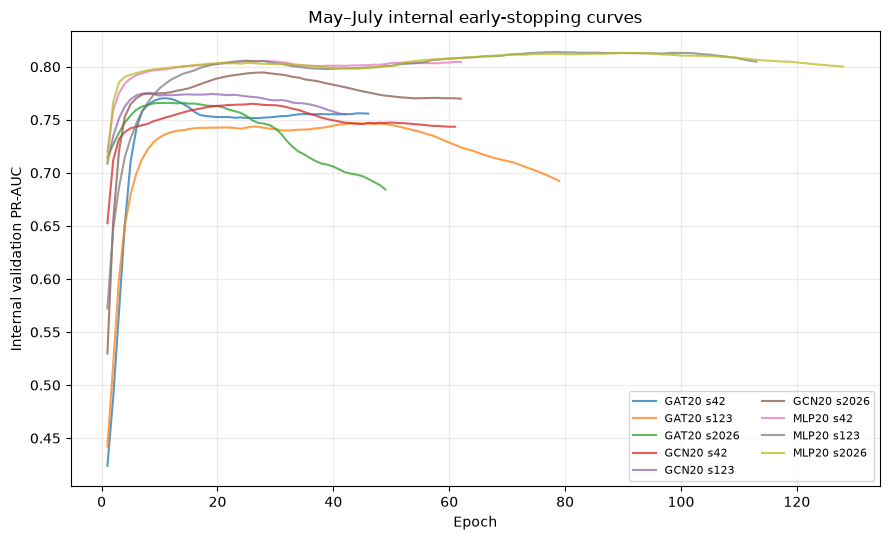

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\figures\02_internal_tuning_curves.png


In [22]:
# 20. Tuning-curve figure

fig, ax = plt.subplots(figsize=(9, 5.5))

for (model_name, seed), group in tuning_history.groupby(["Model", "Seed"]):
    ax.plot(
        group["Epoch"],
        group["Internal PR-AUC"],
        alpha=0.75,
        label=f"{model_name} s{seed}",
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Internal validation PR-AUC")
ax.set_title("May–July internal early-stopping curves")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()

path = FIGURES_DIR / "02_internal_tuning_curves.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 21. Retrain each model on the full May–July window and evaluate August

August is evaluated **after** epoch count has been chosen internally.

In [23]:
# 21. Final full-train neural runs

neural_result_rows = []
final_models = {}
final_val_probs = {}

for row in tuning_summary.itertuples(index=False):
    model_name = row.Model
    seed = int(row.Seed)
    best_epoch = int(row._2) if hasattr(row, "_2") else int(row[2])

    # Robustly retrieve named column with a space
    best_epoch = int(
        tuning_summary.loc[
            (tuning_summary["Model"] == model_name)
            & (tuning_summary["Seed"] == seed),
            "Best Epoch",
        ].iloc[0]
    )

    print(f"Final training {model_name} | seed={seed} | epochs={best_epoch}")

    model, training_seconds, final_loss = train_full_for_epochs(
        model_name,
        seed,
        best_epoch,
    )

    metrics, probability, y_true = evaluate_model_on_indices(
        model,
        val_idx,
    )

    neural_result_rows.append({
        "Model": model_name,
        "Seed": seed,
        "Best Epoch": best_epoch,
        **metrics,
        "Final Training Seconds": training_seconds,
        "Final Train Loss": final_loss,
    })

    final_models[(model_name, seed)] = model
    final_val_probs[(model_name, seed)] = probability


neural_results = pd.DataFrame(neural_result_rows)
display(neural_results)

Final training MLP20 | seed=42 | epochs=27
Final training MLP20 | seed=123 | epochs=78
Final training MLP20 | seed=2026 | epochs=93
Final training GCN20 | seed=42 | epochs=26
Final training GCN20 | seed=123 | epochs=7
Final training GCN20 | seed=2026 | epochs=27
Final training GAT20 | seed=42 | epochs=11
Final training GAT20 | seed=123 | epochs=44
Final training GAT20 | seed=2026 | epochs=14


,Model,Seed,Best Epoch,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold,Final Training Seconds,Final Train Loss
0,MLP20,42,27,0.950285,0.879363,0.844123,0.947872,0.892994,0.829749,0.5,0.273617,0.869591
1,MLP20,123,78,0.955546,0.887970,0.835338,0.963176,0.894713,0.830108,0.5,0.740037,0.795889
2,MLP20,2026,93,0.954868,0.884405,0.821168,0.968436,0.888743,0.818280,0.5,0.919824,0.784668
3,GCN20,42,26,0.936116,0.840462,0.785907,0.976088,0.870734,0.782796,0.5,0.200782,0.849115
4,GCN20,123,7,0.938970,0.844707,0.800317,0.966045,0.875406,0.793907,0.5,0.059296,0.926577
5,GCN20,2026,27,0.935655,0.839762,0.783939,0.980392,0.871228,0.782796,0.5,0.228463,0.847740
6,GAT20,42,11,0.905563,0.783030,0.775464,0.979436,0.865596,0.772043,0.5,1.354739,0.899061
7,GAT20,123,44,0.932972,0.841708,0.764446,0.993305,0.863977,0.765591,0.5,5.301565,0.880469
8,GAT20,2026,14,0.925470,0.823010,0.765596,0.991870,0.864167,0.766308,0.5,1.659628,0.876505


## 22. Aggregate neural results across seeds

The thesis comparison should emphasize **mean and standard deviation**, not only the best seed.

In [24]:
# 22. Seed aggregation

metric_cols = [
    "PR-AUC",
    "ROC-AUC",
    "Precision",
    "Recall",
    "F1",
    "Accuracy",
    "Best Epoch",
    "Final Training Seconds",
]

agg_rows = []

for model_name, group in neural_results.groupby("Model"):
    row = {"Model": model_name, "Seeds": len(group)}

    for metric in metric_cols:
        row[f"{metric} Mean"] = group[metric].mean()
        row[f"{metric} Std"] = group[metric].std(ddof=1)

    agg_rows.append(row)

neural_aggregate = pd.DataFrame(agg_rows)
display(neural_aggregate)

,Model,Seeds,PR-AUC Mean,PR-AUC Std,ROC-AUC Mean,ROC-AUC Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Accuracy Mean,Accuracy Std,Best Epoch Mean,Best Epoch Std,Final Training Seconds Mean,Final Training Seconds Std
0,GAT20,3,0.921335,0.014165,0.815916,0.029975,0.768502,0.006056,0.988203,0.007627,0.864580,0.000885,0.767981,0.003536,23.0,18.248288,2.771978,2.195985
1,GCN20,3,0.936914,0.001796,0.841643,0.002676,0.790054,0.008942,0.974175,0.007362,0.872456,0.002567,0.786499,0.006415,20.0,11.269428,0.162847,0.090740
2,MLP20,3,0.953566,0.002862,0.883913,0.004325,0.833543,0.011582,0.959828,0.010683,0.892150,0.003074,0.826045,0.006728,66.0,34.597688,0.644493,0.333530


# PART F — Fair model comparison

## 23. LR20 vs MLP20 vs GCN20 vs GAT20

Primary metric: **August validation PR-AUC**.

For neural models, the table uses the mean across 3 seeds.

In [25]:
# 23. Main comparison table

comparison_rows = [
    {
        "Model": "LR20",
        "Graph?": False,
        "PR-AUC Mean": lr_metrics["PR-AUC"],
        "PR-AUC Std": 0.0,
        "ROC-AUC Mean": lr_metrics["ROC-AUC"],
        "Precision Mean": lr_metrics["Precision"],
        "Recall Mean": lr_metrics["Recall"],
        "F1 Mean": lr_metrics["F1"],
        "Accuracy Mean": lr_metrics["Accuracy"],
    }
]

for model_name in ["MLP20", "GCN20", "GAT20"]:
    group = neural_results[neural_results["Model"].eq(model_name)]

    comparison_rows.append({
        "Model": model_name,
        "Graph?": model_name in {"GCN20", "GAT20"},
        "PR-AUC Mean": group["PR-AUC"].mean(),
        "PR-AUC Std": group["PR-AUC"].std(ddof=1),
        "ROC-AUC Mean": group["ROC-AUC"].mean(),
        "Precision Mean": group["Precision"].mean(),
        "Recall Mean": group["Recall"].mean(),
        "F1 Mean": group["F1"].mean(),
        "Accuracy Mean": group["Accuracy"].mean(),
    })

main_comparison = pd.DataFrame(comparison_rows)
main_comparison["Δ PR-AUC vs LR20"] = (
    main_comparison["PR-AUC Mean"]
    - lr_metrics["PR-AUC"]
)

display(main_comparison)

,Model,Graph?,PR-AUC Mean,PR-AUC Std,ROC-AUC Mean,Precision Mean,Recall Mean,F1 Mean,Accuracy Mean,Δ PR-AUC vs LR20
0,LR20,False,0.955283,0.000000,0.884426,0.866020,0.939742,0.901376,0.845878,0.000000
1,MLP20,False,0.953566,0.002862,0.883913,0.833543,0.959828,0.892150,0.826045,-0.001716
2,GCN20,True,0.936914,0.001796,0.841643,0.790054,0.974175,0.872456,0.786499,-0.018369
3,GAT20,True,0.921335,0.014165,0.815916,0.768502,0.988203,0.864580,0.767981,-0.033947


## 24. Isolate nonlinear gain vs graph gain

These deltas help interpret *why* a model improves:

- `MLP − LR`: nonlinear capacity without graph;
- `GCN − MLP`: graph convolution beyond node-wise nonlinear modeling;
- `GAT − MLP`: graph attention beyond node-wise nonlinear modeling;
- `GAT − GCN`: learned attention versus fixed normalized graph aggregation.

In [26]:
# 24. Mechanism deltas

mean_ap = dict(zip(main_comparison["Model"], main_comparison["PR-AUC Mean"]))

mechanism_deltas = pd.DataFrame([
    {
        "Comparison": "MLP20 − LR20",
        "Interpretation": "nonlinear capacity beyond linear LR",
        "Δ PR-AUC": mean_ap["MLP20"] - mean_ap["LR20"],
    },
    {
        "Comparison": "GCN20 − MLP20",
        "Interpretation": "fixed graph aggregation beyond node-wise MLP",
        "Δ PR-AUC": mean_ap["GCN20"] - mean_ap["MLP20"],
    },
    {
        "Comparison": "GAT20 − MLP20",
        "Interpretation": "attention graph beyond node-wise MLP",
        "Δ PR-AUC": mean_ap["GAT20"] - mean_ap["MLP20"],
    },
    {
        "Comparison": "GAT20 − GCN20",
        "Interpretation": "learned attention vs fixed graph aggregation",
        "Δ PR-AUC": mean_ap["GAT20"] - mean_ap["GCN20"],
    },
])

display(mechanism_deltas)

,Comparison,Interpretation,Δ PR-AUC
0,MLP20 − LR20,nonlinear capacity beyond linear LR,-0.001716
1,GCN20 − MLP20,fixed graph aggregation beyond node-wise MLP,-0.016653
2,GAT20 − MLP20,attention graph beyond node-wise MLP,-0.032231
3,GAT20 − GCN20,learned attention vs fixed graph aggregation,-0.015578


## 25. Validation PR-AUC comparison figure

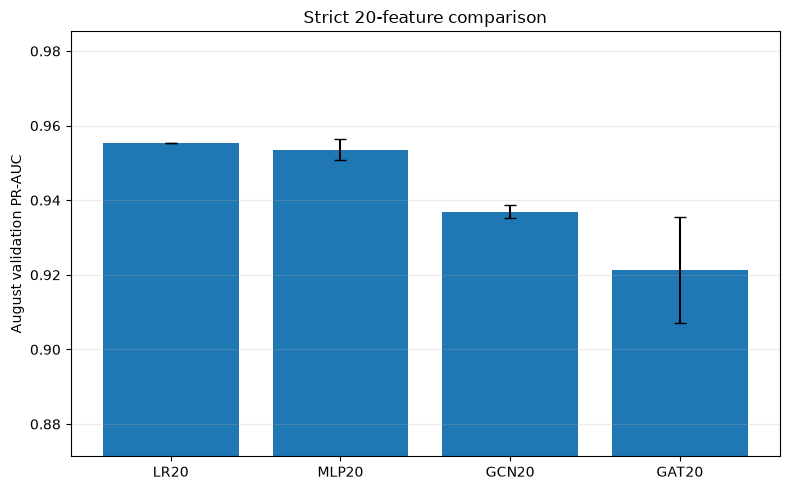

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\figures\03_static_graph_pr_auc_comparison.png


In [27]:
# 25. PR-AUC comparison figure

plot_df = main_comparison.copy()

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(plot_df))
y = plot_df["PR-AUC Mean"].to_numpy()
yerr = plot_df["PR-AUC Std"].to_numpy()

ax.bar(x, y, yerr=yerr, capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"])
ax.set_ylabel("August validation PR-AUC")
ax.set_title("Strict 20-feature comparison")
ax.set_ylim(max(0.0, y.min() - 0.05), min(1.0, y.max() + 0.03))
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()

path = FIGURES_DIR / "03_static_graph_pr_auc_comparison.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART G — Secondary 3-day Emerging-eligible evaluation

## 26. Evaluate the **same overall-trained models** on eligible August rows

This is a subgroup ranking diagnostic, not a separately trained Emerging model.

Eligible row definition:

```text
active_days_prev3_incl_t == 0
```

Unlike the old positive-only subgroup recall, this eligible set contains both negatives and Emerging positives, so PR-AUC is valid.

In [28]:
# 26. Eligible masks aligned to tensor order

val_date_positions = np.where(val_date_mask)[0]
val_eligible_mask = eligible3_np[val_date_mask]
val_y_matrix = y_np[val_date_mask]

eligible_y = val_y_matrix[val_eligible_mask].astype(int)

print("Eligible validation rows     :", len(eligible_y))
print("Eligible Emerging positives :", int(eligible_y.sum()))
print("Eligible positive rate       :", float(eligible_y.mean()))

Eligible validation rows     : 356
Eligible Emerging positives : 61
Eligible positive rate       : 0.17134831460674158


In [29]:
# 27. LR20 eligible validation PR-AUC

# Build row-wise eligible mask in the same order as val_df (date then cell_id)
val_df_sorted = val_df.sort_values(["date", "cell_id"]).reset_index(drop=True)
lr_eligible_mask = val_df_sorted["active_days_prev3_incl_t"].eq(0).to_numpy()

lr_eligible_metrics = metric_dict(
    val_df_sorted.loc[lr_eligible_mask, target_col].astype(int).to_numpy(),
    lr_val_prob[lr_eligible_mask],
    threshold=0.50,
)

eligible_result_rows = [
    {
        "Model": "LR20",
        "Seed": np.nan,
        **lr_eligible_metrics,
    }
]

for (model_name, seed), probability_matrix in final_val_probs.items():
    metrics = metric_dict(
        eligible_y,
        probability_matrix[val_eligible_mask],
        threshold=0.50,
    )

    eligible_result_rows.append({
        "Model": model_name,
        "Seed": seed,
        **metrics,
    })

eligible_model_results = pd.DataFrame(eligible_result_rows)
display(eligible_model_results)

,Model,Seed,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR20,NaN,0.390415,0.694749,0.451613,0.459016,0.455285,0.811798,0.5
1,MLP20,42.0,0.366782,0.690525,0.301887,0.524590,0.383234,0.710674,0.5
2,MLP20,123.0,0.396504,0.709919,0.346939,0.557377,0.427673,0.744382,0.5
3,MLP20,2026.0,0.386921,0.714532,0.316239,0.606557,0.415730,0.707865,0.5
4,GCN20,42.0,0.257145,0.618061,0.208000,0.852459,0.334405,0.418539,0.5
5,GCN20,123.0,0.285793,0.641789,0.225806,0.803279,0.352518,0.494382,0.5
6,GCN20,2026.0,0.276038,0.619005,0.206349,0.852459,0.332268,0.412921,0.5
7,GAT20,42.0,0.272787,0.633120,0.209622,1.000000,0.346591,0.353933,0.5
8,GAT20,123.0,0.292306,0.635343,0.190789,0.950820,0.317808,0.300562,0.5
9,GAT20,2026.0,0.229676,0.563823,0.194805,0.983607,0.325203,0.300562,0.5


In [30]:
# 28. Eligible-task aggregate comparison

eligible_aggregate_rows = [
    {
        "Model": "LR20",
        "PR-AUC Mean": lr_eligible_metrics["PR-AUC"],
        "PR-AUC Std": 0.0,
        "Precision Mean": lr_eligible_metrics["Precision"],
        "Recall Mean": lr_eligible_metrics["Recall"],
        "F1 Mean": lr_eligible_metrics["F1"],
    }
]

for model_name in ["MLP20", "GCN20", "GAT20"]:
    group = eligible_model_results[eligible_model_results["Model"].eq(model_name)]
    eligible_aggregate_rows.append({
        "Model": model_name,
        "PR-AUC Mean": group["PR-AUC"].mean(),
        "PR-AUC Std": group["PR-AUC"].std(ddof=1),
        "Precision Mean": group["Precision"].mean(),
        "Recall Mean": group["Recall"].mean(),
        "F1 Mean": group["F1"].mean(),
    })

eligible_aggregate = pd.DataFrame(eligible_aggregate_rows)
eligible_aggregate["Δ PR-AUC vs LR20"] = (
    eligible_aggregate["PR-AUC Mean"]
    - lr_eligible_metrics["PR-AUC"]
)

display(eligible_aggregate)

,Model,PR-AUC Mean,PR-AUC Std,Precision Mean,Recall Mean,F1 Mean,Δ PR-AUC vs LR20
0,LR20,0.390415,0.000000,0.451613,0.459016,0.455285,0.000000
1,MLP20,0.383402,0.015170,0.321688,0.562842,0.408879,-0.007012
2,GCN20,0.272992,0.014565,0.213385,0.836066,0.339731,-0.117423
3,GAT20,0.264923,0.032047,0.198406,0.978142,0.329867,-0.125492


## 29. Persistent vs Emerging positive recall

Recall is reported separately for positive subgroups only as a descriptive diagnostic.

Precision and PR-AUC are **not** computed inside these all-positive subgroup slices.

In [31]:
# 29. Positive subgroup recall

val_event_matrix = event3_np[val_date_mask]

subgroup_rows = []

# LR row probabilities aligned as [date, node]
lr_prob_matrix = lr_val_prob.reshape(len(val_dates), N_NODES)

prob_sources = {"LR20": [(None, lr_prob_matrix)]}

for model_name in ["MLP20", "GCN20", "GAT20"]:
    prob_sources[model_name] = [
        (seed, final_val_probs[(model_name, seed)])
        for seed in SEEDS
    ]

for model_name, seed_prob_list in prob_sources.items():
    for seed, prob_matrix in seed_prob_list:
        for event_type in ["Persistent", "Emerging"]:
            mask = (
                (val_event_matrix == event_type)
                & (val_y_matrix == 1)
            )

            n = int(mask.sum())
            if n == 0:
                recall = np.nan
                mean_prob = np.nan
            else:
                recall = float((prob_matrix[mask] >= 0.50).mean())
                mean_prob = float(prob_matrix[mask].mean())

            subgroup_rows.append({
                "Model": model_name,
                "Seed": seed,
                "Event Type": event_type,
                "N Positives": n,
                "Recall @0.50": recall,
                "Mean Probability": mean_prob,
            })

subgroup_recall = pd.DataFrame(subgroup_rows)
display(subgroup_recall)

,Model,Seed,Event Type,N Positives,Recall @0.50,Mean Probability
0,LR20,NaN,Persistent,2030,0.952217,0.905958
1,LR20,NaN,Emerging,61,0.475410,0.507761
2,MLP20,42.0,Persistent,2030,0.960591,0.894085
3,MLP20,42.0,Emerging,61,0.524590,0.490432
4,MLP20,123.0,Persistent,2030,0.975369,0.910310
5,MLP20,123.0,Emerging,61,0.557377,0.508102
6,MLP20,2026.0,Persistent,2030,0.979310,0.909011
7,MLP20,2026.0,Emerging,61,0.606557,0.519650
8,GCN20,42.0,Persistent,2030,0.979803,0.939081
9,GCN20,42.0,Emerging,61,0.852459,0.709483


# PART H — GAT attention diagnostic

## 30. Inspect average first-layer attention from the representative GAT seed

Attention weights are useful for debugging whether the model differentiates neighbors, but they are **not automatically causal explanations**.

In [32]:
# 30. Mean GAT attention across August and heads

REPRESENTATIVE_SEED = SEEDS[0]
gat_model = final_models[("GAT20", REPRESENTATIVE_SEED)]
gat_model.eval()

with torch.no_grad():
    gat_logits, gat_attention = gat_model(
        X_tensor[val_idx],
        A_norm_tensor,
        adj_mask_tensor,
        return_attention=True,
    )

# gat_attention: [date, target, source, head]
mean_attention = (
    gat_attention
    .mean(dim=(0, 3))
    .detach()
    .cpu()
    .numpy()
)

attention_rows = []

for row in edges.itertuples(index=False):
    source_pos = cell_to_pos[row.source_cell_id]
    target_pos = cell_to_pos[row.target_cell_id]

    attention_rows.append({
        "source_cell_id": row.source_cell_id,
        "target_cell_id": row.target_cell_id,
        "distance_km": row.distance_km,
        "mean_august_attention": float(mean_attention[target_pos, source_pos]),
    })

attention_summary = (
    pd.DataFrame(attention_rows)
    .sort_values("mean_august_attention", ascending=False)
    .reset_index(drop=True)
)

display(attention_summary.head(20))

,source_cell_id,target_cell_id,distance_km,mean_august_attention
0,Kalimantan_0.75_110.25,Kalimantan_1.50_109.50,117.928405,0.394334
1,Kalimantan_-2.25_110.25,Kalimantan_-3.00_110.25,83.396310,0.365016
2,Kalimantan_-2.25_110.25,Kalimantan_-3.00_111.00,117.877907,0.354974
3,Kalimantan_-3.00_116.25,Kalimantan_-3.75_115.50,117.837534,0.332505
4,Kalimantan_-2.25_114.00,Kalimantan_-1.50_114.75,117.908201,0.322606
5,Kalimantan_2.25_117.75,Kalimantan_1.50_118.50,117.908201,0.317977
6,Kalimantan_0.00_109.50,Kalimantan_0.75_108.75,117.938509,0.315027
7,Kalimantan_-2.25_113.25,Kalimantan_-1.50_112.50,117.908201,0.314898
8,Kalimantan_-3.00_115.50,Kalimantan_-3.00_116.25,83.282017,0.310606
9,Kalimantan_-3.00_115.50,Kalimantan_-2.25_116.25,117.877907,0.306819


## 31. Attention distribution by distance

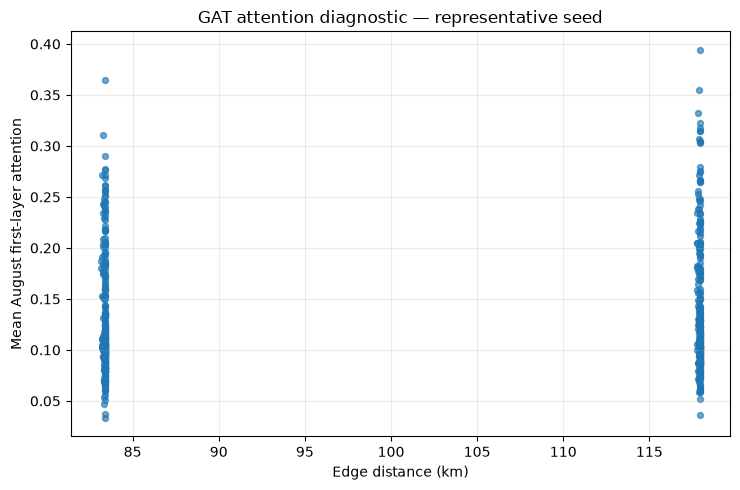

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\figures\04_gat_attention_vs_distance.png


In [33]:
# 31. Distance vs attention plot

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(
    attention_summary["distance_km"],
    attention_summary["mean_august_attention"],
    s=18,
    alpha=0.65,
)
ax.set_xlabel("Edge distance (km)")
ax.set_ylabel("Mean August first-layer attention")
ax.set_title("GAT attention diagnostic — representative seed")
ax.grid(alpha=0.25)
plt.tight_layout()

path = FIGURES_DIR / "04_gat_attention_vs_distance.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART I — Runtime / hardware summary

## 32. Training cost

This directly answers the practical question of whether a larger GPU is necessary for the static 90-node graph.

In [34]:
# 32. Runtime summary

runtime_summary = (
    neural_results
    .groupby("Model", as_index=False)
    .agg(
        Mean_Best_Epoch=("Best Epoch", "mean"),
        Mean_Final_Training_Seconds=("Final Training Seconds", "mean"),
        Max_Final_Training_Seconds=("Final Training Seconds", "max"),
    )
)

runtime_summary["Device"] = str(DEVICE)

display(runtime_summary)

print(
    "Interpretation: with 90 nodes and a dense 150-km adjacency matrix, "
    "static GCN/GAT is a small graph problem. GPU acceleration may shorten "
    "experiments, but a large GPU is not structurally required for Notebook 14."
)

,Model,Mean_Best_Epoch,Mean_Final_Training_Seconds,Max_Final_Training_Seconds,Device
0,GAT20,23.0,2.771978,5.301565,cpu
1,GCN20,20.0,0.162847,0.228463,cpu
2,MLP20,66.0,0.644493,0.919824,cpu


Interpretation: with 90 nodes and a dense 150-km adjacency matrix, static GCN/GAT is a small graph problem. GPU acceleration may shorten experiments, but a large GPU is not structurally required for Notebook 14.


# PART J — Save artifacts for Notebook 15

## 33. Save model-ready graph tensors and metadata

Notebook 15 can reuse these exact standardized node snapshots and graph matrices to build temporal sequences.

In [35]:
# 33. Save graph inputs

np.savez_compressed(
    ARTIFACTS_DIR / "graph_inputs_r150km.npz",
    X_scaled=X_scaled,
    y=y_np,
    eligible3=eligible3_np,
    dates=np.array([str(d.date()) for d in all_dates]),
    node_ids=node_order["cell_id"].astype(str).to_numpy(),
    A_norm=A_norm,
    adj_mask=adj_mask.astype(np.uint8),
)

node_order.to_csv(
    ARTIFACTS_DIR / "graph_node_order.csv",
    index=False,
)

edges.to_csv(
    ARTIFACTS_DIR / "graph_edges_r150km.csv",
    index=False,
)

if joblib is not None:
    joblib.dump(
        scaler,
        ARTIFACTS_DIR / "feature_scaler_20.joblib",
    )

print("Saved graph artifacts to:", ARTIFACTS_DIR)

Saved graph artifacts to: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\artifacts


## 34. Save result tables and representative model states

In [36]:
# 34. Save tables and model states

tables = {
    "parameter_table.csv": parameter_table,
    "tuning_summary.csv": tuning_summary,
    "tuning_history.csv": tuning_history,
    "neural_seed_results.csv": neural_results,
    "neural_aggregate.csv": neural_aggregate,
    "main_comparison.csv": main_comparison,
    "mechanism_deltas.csv": mechanism_deltas,
    "eligible_model_results.csv": eligible_model_results,
    "eligible_aggregate.csv": eligible_aggregate,
    "subgroup_recall.csv": subgroup_recall,
    "gat_attention_summary.csv": attention_summary,
    "runtime_summary.csv": runtime_summary,
}

for filename, dataframe in tables.items():
    path = RESULTS_DIR / filename
    dataframe.to_csv(path, index=False)
    print("Saved:", path)

for (model_name, seed), model in final_models.items():
    path = MODELS_DIR / f"{model_name.lower()}_seed{seed}.pt"
    torch.save(model.state_dict(), path)

print("Saved model states to:", MODELS_DIR)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\parameter_table.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\tuning_summary.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\tuning_history.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\neural_seed_results.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\neural_aggregate.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\main_comparison.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\mechanism_deltas.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\eligible_model_results.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\eligible_aggregate.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\static_g

# PART K — Keep September test unopened

In [37]:
# 35. Final-test lock

RUN_TEST = False

if RUN_TEST:
    print(
        "Do not evaluate September yet. Lock the temporal model architecture first, "
        "then perform one final test evaluation later."
    )
else:
    print("RUN_TEST=False → September test probabilities were not generated.")

RUN_TEST=False → September test probabilities were not generated.


# 36. Automatic decision summary

The next step depends on **graph gain beyond MLP**, not merely whether GAT beats LR.

In [38]:
# 36. Automatic interpretation

lr_ap = mean_ap["LR20"]
mlp_ap = mean_ap["MLP20"]
gcn_ap = mean_ap["GCN20"]
gat_ap = mean_ap["GAT20"]

eligible_map = dict(zip(eligible_aggregate["Model"], eligible_aggregate["PR-AUC Mean"]))

print("=== Notebook 14 static graph summary ===")
print()
print("DEVICE")
print("Device                     :", DEVICE)
print("Nodes                      :", N_NODES)
print("150-km directed edges      :", len(edges))
print()
print("AUGUST VALIDATION — STRICT 20 FEATURES")
print("LR20 PR-AUC                :", round(lr_ap, 6))
print("MLP20 mean PR-AUC          :", round(mlp_ap, 6))
print("GCN20 mean PR-AUC          :", round(gcn_ap, 6))
print("GAT20 mean PR-AUC          :", round(gat_ap, 6))
print()
print("MECHANISM DELTAS")
print("MLP − LR                   :", f"{mlp_ap - lr_ap:+.6f}")
print("GCN − MLP                  :", f"{gcn_ap - mlp_ap:+.6f}")
print("GAT − MLP                  :", f"{gat_ap - mlp_ap:+.6f}")
print("GAT − GCN                  :", f"{gat_ap - gcn_ap:+.6f}")
print()
print("3-DAY EMERGING-ELIGIBLE PR-AUC")
print("LR20                        :", round(eligible_map["LR20"], 6))
print("MLP20                       :", round(eligible_map["MLP20"], 6))
print("GCN20                       :", round(eligible_map["GCN20"], 6))
print("GAT20                       :", round(eligible_map["GAT20"], 6))
print()

if gat_ap > mlp_ap and gat_ap > gcn_ap:
    print(
        "GAT shows positive graph-specific validation gain beyond the node-wise MLP "
        "and fixed GCN under the strict 20-feature comparison."
    )
elif gcn_ap > mlp_ap or gat_ap > mlp_ap:
    print(
        "At least one graph model improves over the node-wise MLP, suggesting that "
        "static graph structure contains some additional predictive information."
    )
else:
    print(
        "Neither static graph model improves over the node-wise MLP. The next test "
        "should focus on whether temporal graph modeling—not static graph structure "
        "alone—is the missing representation."
    )

print()
print(
    "NEXT: build Notebook 15 as a temporal graph model (GAT/GCN per day followed by "
    "GRU/LSTM across 7–14 days). Wind should remain a later ablation, not the default edge model."
)

=== Notebook 14 static graph summary ===

DEVICE
Device                     : cpu
Nodes                      : 90
150-km directed edges      : 590

AUGUST VALIDATION — STRICT 20 FEATURES
LR20 PR-AUC                : 0.955283
MLP20 mean PR-AUC          : 0.953566
GCN20 mean PR-AUC          : 0.936914
GAT20 mean PR-AUC          : 0.921335

MECHANISM DELTAS
MLP − LR                   : -0.001716
GCN − MLP                  : -0.016653
GAT − MLP                  : -0.032231
GAT − GCN                  : -0.015578

3-DAY EMERGING-ELIGIBLE PR-AUC
LR20                        : 0.390415
MLP20                       : 0.383402
GCN20                       : 0.272992
GAT20                       : 0.264923

Neither static graph model improves over the node-wise MLP. The next test should focus on whether temporal graph modeling—not static graph structure alone—is the missing representation.

NEXT: build Notebook 15 as a temporal graph model (GAT/GCN per day followed by GRU/LSTM across 7–14 days). Wind

# What to send for review

After running Notebook 14, send these outputs:

1. **Section 17** — parameter counts and fixed configs
2. **Section 19** — internal tuning summary
3. **Section 22** — neural seed aggregation
4. **Section 23** — main LR/MLP/GCN/GAT comparison
5. **Section 24** — mechanism deltas
6. **Section 28** — 3-day Emerging-eligible comparison
7. **Section 32** — runtime summary
8. **Section 36** — automatic interpretation

Also send screenshots of:

- `03_static_graph_pr_auc_comparison.png`
- `04_gat_attention_vs_distance.png`

Do **not** turn on the September test yet.